# Ticket intake model: escalation → category / sub-category

**Two-stage model built on sentence embeddings (all-MiniLM-L6-v2) and logistic regression.**

| Stage | Predicts | Inputs (all known when the ticket arrives) | Possible outputs |
|---|---|---|---|
| 1 | Escalation | description embedding, priority, client support tier | `1`, `0`, or **ABSTAIN** |
| 2 | Category + sub-category pair | description embedding | pair, **category only**, or **ABSTAIN** |

**Data use (agreed earlier):**
* Build, tune and evaluate on the **new** set only.
* Use the **old** set only as an out-of-distribution test of the refusal logic, with no training or tuning on it.
* Incidents are ignored.

**Avoiding hallucination.** The model refuses instead of guessing when:
1. the description is unlike anything seen in training (nearest-neighbour similarity below a threshold set on validation data);
2. the probability falls inside an uncertain band (thresholds set on validation folds to hit target precision and NPV);
3. the sub-category is uncertain but the category is clear. It then answers **category only**.

Predicting the *pair* as one label means the model can never produce a category/sub-category combination that doesn't exist.

**Evaluation**
* **Nested, grouped cross-validation.**
  * 5 outer folds are used for testing.
  * Inside each outer-training split, 3 inner folds pick `C` and all refusal thresholds.
  * Test folds are never used for tuning.
* **Six grouping systems** decide which tickets must be kept together in the same fold:
  * random (no grouping, the leakage baseline);
  * client;
  * exact short description;
  * description template;
  * semantic clusters at k=50 and k=200.
* **Extra checks:** a temporal hold-out (train Jan–Apr, test May–Jun), and the old-set refusal test.

> ⚠️ The data is synthetic. Metrics show the pipeline works on the generator's patterns. They are **not** estimates of real-world performance.

In [1]:
import sys, re, json, time, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, f1_score
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = Path.cwd() if (Path.cwd() / "artifacts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from embedder import MiniLMEmbedder

# ---------------- configuration ----------------
SEED = 42
N_OUTER, N_INNER = 5, 3
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
STAGE1_PREC_TARGET = 0.50   # predict "1" only where validated precision >= 50% (base rate is ~10%)
STAGE1_NPV_TARGET  = 0.95   # predict "0" only where validated negative predictive value >= 95%
STAGE2_ACC_TARGET  = 0.90   # answer a pair / category only where validated accuracy >= 90%
MIN_SUPPORT        = 30     # a threshold needs at least this many validation cases behind it
OOD_PERCENTILE     = 1.0    # refuse if nearest-neighbour similarity < 1st percentile seen on validation
PRIMARY_GROUPING   = "template"
NOVELTY_GROUPING   = "semantic_k50"   # stage-2 refusal thresholds must also hold when whole topics are unseen
RISK_BAND_EDGES    = [0.05, 0.15, 0.40]
RISK_BAND_NAMES    = ["Low", "Typical", "Elevated", "High"]
GROUPINGS = ["random", "client", "short_desc", "template", "semantic_k200", "semantic_k50"]

# reference palette (dataviz skill), light mode
C1, C2, C3, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK})
print("project root:", ROOT)

project root: /home/claude/project


## 1. Load data and clean the description text

The text sent to the embedding model is the **short description + the body of the request**. These parts are removed:
* greetings and sign-offs, which are boilerplate and carry the client code;
* quoted "earlier message" repeats;
* `[Support note: linked to service issue …]` lines, which are added after the fact and would leak information;
* any client codes left in the text.

In [2]:
new = pd.read_excel(ROOT / "data/New_Case_details_synthetic_v5.xlsx", sheet_name="Cases")
old = pd.read_excel(ROOT / "data/Case_details_synthetic_v3.1.xlsx", sheet_name="Sheet1")

GREETING = re.compile(r"^(hi|hello|hey|dear|good (morning|afternoon|evening))\b[^\n]{0,40}$", re.I)
SIGNOFF  = re.compile(r"^(kind regards|best regards|warm regards|regards|many thanks|thanks|thank you|cheers|best)\b", re.I)

def clean_text(short, desc):
    desc = "" if pd.isna(desc) else str(desc)
    desc = desc.split("----- Earlier message -----")[0]
    desc = re.sub(r"\[Support note:[^\]]*\]", " ", desc)
    lines = [l.strip() for l in desc.strip().split("\n") if l.strip()]
    if lines and GREETING.match(lines[0]):
        lines = lines[1:]
    for i, l in enumerate(lines):
        if SIGNOFF.match(l):
            lines = lines[:i]; break
    body = " ".join(lines)
    short = "" if pd.isna(short) else str(short).strip()
    text = f"{short}. {body}" if short and body and short.lower() not in body.lower() else (body or short)
    return re.sub(r"\b(CX|CL)\d{4}\b", "", text).strip()

new["text"] = [clean_text(s, d) for s, d in zip(new.SHORT_DESCRIPTION, new.CASE_DESCRIPTION)]
new["y_esc"] = (new.ESCALATION == "Escalated").astype(int)
new["pair"] = np.where(new.CATEGORY.notna() & new.SUB_CATEGORY.notna(),
                       new.CATEGORY.astype(str) + " || " + new.SUB_CATEGORY.astype(str), None)
PAIR = new.pair.to_numpy(dtype=object)   # plain numpy arrays (pandas 3 string arrays do not broadcast)
new["PRIORITY"] = new.PRIORITY.fillna("NA"); new["CLIENT_SUPPORT"] = new.CLIENT_SUPPORT.fillna("NA")

old["text"] = [clean_text(s, d) for s, d in zip(old["Short description"], old["masked_description"])]
old["y_esc"] = (old.Escalation == "Escalated").astype(int)
old["pair"] = np.where(old.Category.notna() & old["Sub Category"].notna(),
                       old.Category.astype(str) + " || " + old["Sub Category"].astype(str), None)
old = old.rename(columns={"Priority": "PRIORITY", "Client Support": "CLIENT_SUPPORT", "Category": "CATEGORY"})

print(f"new: {len(new):,} cases | escalation rate {new.y_esc.mean():.3f} | labelled pairs {new.pair.notna().sum():,} "
      f"({new.pair.nunique()} distinct) | empty text {(new.text == '').sum()}")
print(f"old: {len(old):,} cases | escalation rate {old.y_esc.mean():.3f} | pairs {old.pair.nunique()} | unlabelled {old.pair.isna().sum()}")
for i in [0, 1, 4]:
    print("\nRAW  :", repr(new.CASE_DESCRIPTION.iloc[i][:160])); print("CLEAN:", new.text.iloc[i])

new: 29,350 cases | escalation rate 0.102 | labelled pairs 28,750 (59 distinct) | empty text 0
old: 2,636 cases | escalation rate 0.850 | pairs 39 | unlabelled 10

RAW  : 'Hello Support,\n\nThe commitment shown on the Mar 2024 statement for Fund FD-996 looks incorrect.\n\nKind regards,\nMiddle Office Associate, CX4090'
CLEAN: Capital account question. The commitment shown on the Mar 2024 statement for Fund FD-996 looks incorrect.

RAW  : 'Good afternoon,\n\nWhere can I find the screen showing Cash Flow Report?\n\nKind regards,\nRisk Analyst, CX7777'
CLEAN: How-to question. Where can I find the screen showing Cash Flow Report?

RAW  : 'Hello,\n\nSeveral orders for Portfolio PT-7911 are stuck since this morning. Please advise urgently, the desk is waiting.\n\nBest regards,\nRisk Analyst, CX8586'
CLEAN: Order order OR-284380 still pending. Several orders for Portfolio PT-7911 are stuck since this morning. Please advise urgently, the desk is waiting.


## 2. Sentence embeddings

* **Model:** `sentence-transformers/all-MiniLM-L6-v2`, run through onnxruntime.
  * The ONNX weights come from the Spring AI repository on GitHub. Their SHA-256 matches the Git LFS pointer.
  * Tokenisation uses a pure-Python WordPiece implementation.
  * Output is a mean-pooled, L2-normalised 384-dimensional vector, the same as `SentenceTransformer.encode(..., normalize_embeddings=True)`.
* **Caching:** embeddings are cached to `artifacts/` and keyed by a hash of the text.

In [3]:
embedder = MiniLMEmbedder(str(ROOT / "artifacts/model.onnx"), str(ROOT / "artifacts/tokenizer.json"))

def embed_cached(texts, name):
    h = hashlib.sha256("\x1f".join(texts).encode()).hexdigest()[:16]
    f = ROOT / f"artifacts/emb_{name}_{h}.npy"
    if f.exists():
        return np.load(f)
    t = time.time(); E = embedder.encode(list(texts)); np.save(f, E)
    print(f"embedded {len(texts):,} texts in {time.time() - t:.0f}s")
    return E

E_new = embed_cached(new.text.tolist(), "new")
E_old = embed_cached(old.text.tolist(), "old")
print(E_new.shape, E_old.shape, "norms ~1:", np.round(np.linalg.norm(E_new[:3], axis=1), 4))

# sanity check: nearest neighbour of a few cases should be the same kind of request
for i in [0, 100, 2000]:
    s = E_new @ E_new[i]; s[i] = -1; j = int(s.argmax())
    print(f"\n[{new.pair.iloc[i]}] {new.text.iloc[i][:90]}\n  NN sim={s[j]:.3f} [{new.pair.iloc[j]}] {new.text.iloc[j][:90]}")

(29350, 384) (2636, 384) norms ~1: [1. 1. 1.]

[Investor Services || Statement query] Capital account question. The commitment shown on the Mar 2024 statement for Fund FD-996 l
  NN sim=0.990 [Investor Services || Statement query] Capital account question. The commitment shown on the Mar 2024 statement for Fund FD-926 l

[Reconciliation || Position break] Position break - Portfolio PT-4583. There is a position break on Instrument IS-34680 in Po
  NN sim=0.986 [Reconciliation || Position break] Position break - Portfolio PT-4585. There is a position break on Instrument IS-45513 in Po

[Trade Workflow || Trade amendment] Trade correction request. Please help us amend the quantity on trade order OR-626741 for P
  NN sim=0.982 [Trade Workflow || Trade amendment] Trade correction request. Please help us amend the quantity on trade order OR-637597 for P


## 3. Grouping systems for the descriptions

Synthetic tickets come from templates, so the same wording shows up many times with only the IDs, dates and amounts changed. If copies of one template end up in both the training and the test folds, the model just remembers that wording and the scores come out too high. Each grouping system below keeps a set of related tickets together in a single fold.

| Grouping | Tickets kept together | What it tests |
|---|---|---|
| `random` | none | Baseline with no grouping; shows how much leakage inflates scores |
| `client` | same client code | Clients the model has never seen |
| `short_desc` | identical short description | New subject lines |
| `template` | same description once IDs, dates, amounts and numbers are masked | **New wordings of requests (primary)** |
| `semantic_k200` / `semantic_k50` | the same KMeans cluster of embeddings | Requests unlike anything in training. Hardest at k=50, where whole topics can be held out |

In [4]:
MONTHS = r"(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"
def template(s):
    s = s.lower()
    s = re.sub(r"\b[a-z]{1,4}-\d+\b", "<id>", s)
    s = re.sub(rf"\b\d{{1,2}} {MONTHS} \d{{4}}\b", "<date>", s)
    s = re.sub(rf"\b{MONTHS} \d{{4}}\b|\bq[1-4] \d{{4}}\b|\bfy ?\d{{2,4}}\b", "<period>", s)
    s = re.sub(r"\b(usd|sgd|eur|gbp|jpy|aud|chf|hkd|cad)\s?[\d.,]+\s?[mkb]?n?\b", "<amt>", s)
    s = re.sub(r"\d+([.,]\d+)?", "<n>", s)
    return re.sub(r"\s+", " ", s).strip()

new["g_template"] = new.text.map(template)
km200 = MiniBatchKMeans(200, random_state=SEED, n_init=3, batch_size=4096).fit(E_new)
km50  = MiniBatchKMeans(50,  random_state=SEED, n_init=3, batch_size=4096).fit(E_new)
group_cols = {
    "random": None,
    "client": new.ABBREVIATION.fillna(pd.Series([f"NA_{i}" for i in range(len(new))], index=new.index)),
    "short_desc": new.SHORT_DESCRIPTION.fillna("").str.strip().str.lower(),
    "template": new.g_template,
    "semantic_k200": pd.Series(km200.labels_, index=new.index).astype(str),
    "semantic_k50":  pd.Series(km50.labels_,  index=new.index).astype(str),
}
rows = []
for g, col in group_cols.items():
    if col is None:
        rows.append({"grouping": g, "groups": len(new), "largest group": 1, "median size": 1, "pairs per group (mean)": 1.0}); continue
    sz = col.value_counts()
    ppg = new.groupby(col.values).pair.nunique().mean()
    rows.append({"grouping": g, "groups": len(sz), "largest group": int(sz.max()), "median size": float(sz.median()),
                 "pairs per group (mean)": round(ppg, 2)})
grouping_summary = pd.DataFrame(rows).set_index("grouping")
print("Example templates:"); print(new.g_template.value_counts().head(5).to_string())
grouping_summary

Example templates:
g_template
price query for instrument <id>. the price for instrument <id> has not changed for <n> days. please check whether it is stale.                                        436
stale price - instrument <id>. the price for instrument <id> has not changed for <n> days. please check whether it is stale.                                          421
coupon/maturity wrong for instrument <id>. the coupon and maturity for instrument <id> look incorrect. please verify and correct.                                     408
portfolio <id> holdings differ from our records. holdings for portfolio <id> as of <date> do not match our records. instrument <id> quantity differs by <n> units.    400
instrument <id> attributes incorrect. the coupon and maturity for instrument <id> look incorrect. please verify and correct.                                          391


,groups,largest group,median size,pairs per group (mean)
grouping,,,,
random,29350,1,1.0,1.00
client,929,3459,10.0,12.26
short_desc,12816,388,1.0,0.99
template,3076,436,1.0,0.99
semantic_k200,200,490,114.0,1.72
semantic_k50,50,1077,584.5,2.66


## 4. Model, refusal rules and nested cross-validation

**Stage 1 (escalation).**
* Model: `StandardScaler → LogisticRegression` on `[embedding | one-hot priority | one-hot client tier]`, with no class weighting so the probabilities stay calibrated.
* The inner folds supply out-of-fold probabilities for picking `C` (lowest log-loss) and two thresholds:
  * `t_hi`, the lowest threshold where validated precision is at least 50%. At or above it the model answers **1**;
  * `t_lo`, the highest threshold where validated NPV is at least 95%. Below it the model answers **0**;
  * between the two it answers **ABSTAIN**.
  * If no threshold can meet a target with at least 30 validation cases behind it, the model never gives that answer.

**Stage 2 (pair).**
* Model: multinomial `LogisticRegression` on the embedding. Category probability is the sum of its pairs' probabilities.
* Thresholds are validated twice: on inner folds of the current grouping, and on "novelty" folds where whole semantic clusters (k=50) are held out. The stricter of the two is kept, so the thresholds also hold on topics the model has never seen.
* The validated thresholds give three possible answers:
  * the **pair** if pair confidence is at least `t_pair`;
  * the **category only** if category confidence is at least `t_cat`;
  * otherwise **ABSTAIN**.

**Out-of-distribution rule (both stages).** If a ticket's cosine similarity to its nearest training description is below the 1st percentile seen on validation, the model answers **ABSTAIN** for both stages.

In [5]:
def onehot(df, cols, levels=None):
    levels = levels or {c: sorted(df[c].astype(str).unique()) for c in cols}
    mats = [(df[c].astype(str).to_numpy(dtype=object)[:, None] == np.array(levels[c])[None, :]).astype(np.float32) for c in cols]
    return np.hstack(mats), levels

STRUCT_COLS = ["PRIORITY", "CLIENT_SUPPORT"]
X_struct_new, STRUCT_LEVELS = onehot(new, STRUCT_COLS)

def features(kind, idx=None, E=E_new, Xs=X_struct_new):
    idx = slice(None) if idx is None else idx
    if kind == "structured": return Xs[idx]
    if kind == "embedding":  return E[idx]
    return np.hstack([E[idx], Xs[idx]])

def max_sim(A, B, chunk=2048):
    out = np.empty(len(A), dtype=np.float32)
    for i in range(0, len(A), chunk):
        out[i:i + chunk] = (A[i:i + chunk] @ B.T).max(1)
    return out

def make_lr(C, multiclass=False):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, random_state=SEED))

def splitter(grouping, n, seed=SEED):
    return StratifiedKFold(n, shuffle=True, random_state=seed) if grouping == "random" else \
           StratifiedGroupKFold(n, shuffle=True, random_state=seed)

def split(grouping, idx, strat, n, seed=SEED):
    g = None if grouping == "random" else group_cols[grouping].to_numpy(dtype=object)[idx]
    return list(splitter(grouping, n, seed).split(np.zeros(len(idx)), strat, g))

# ---------- threshold selection (validation data only) ----------
def stage1_thresholds(p, y):
    qs = np.unique(np.quantile(p, np.linspace(0, 1, 401)))
    t_hi = np.inf
    for t in qs:                                   # lowest t with precision >= target  -> most coverage
        m = p >= t
        if m.sum() >= MIN_SUPPORT and y[m].mean() >= STAGE1_PREC_TARGET:
            t_hi = t; break
    t_lo = -np.inf
    for t in qs[::-1]:                             # highest t with NPV >= target       -> most coverage
        m = p < t
        if m.sum() >= MIN_SUPPORT and (1 - y[m].mean()) >= STAGE1_NPV_TARGET:
            t_lo = t; break
    return float(min(t_lo, t_hi)), float(t_hi)

def conf_threshold(conf, correct):
    for t in np.unique(np.quantile(conf, np.linspace(0, 1, 401))):
        m = conf >= t
        if m.sum() >= MIN_SUPPORT and correct[m].mean() >= STAGE2_ACC_TARGET:
            return float(t)
    return np.inf

def ood_threshold(E_tr, inner_splits):
    sims = np.concatenate([max_sim(E_tr[va], E_tr[tr]) for tr, va in inner_splits])
    return float(np.percentile(sims, OOD_PERCENTILE))

def cat_probs(P, classes):
    cats = np.array([c.split(" || ")[0] for c in classes]); ucats = np.unique(cats)
    return np.stack([P[:, cats == u].sum(1) for u in ucats], 1), ucats

def stage1_decide(p, t_lo, t_hi, ood):
    d = np.full(len(p), "ABSTAIN", dtype=object)
    d[p >= t_hi] = "1"; d[p < t_lo] = "0"; d[ood] = "ABSTAIN"
    return d

def stage2_decide(P, classes, t_pair, t_cat, ood):
    Pc, ucats = cat_probs(P, classes)
    pair, cat = classes[P.argmax(1)], ucats[Pc.argmax(1)]
    mode = np.where(P.max(1) >= t_pair, "pair", np.where(Pc.max(1) >= t_cat, "category", "ABSTAIN")).astype(object)
    mode[ood] = "ABSTAIN"
    return pair, cat, mode

In [6]:
def fit_stage1(idx_tr, grouping, feat, seed=SEED):
    # inner grouped CV on the training indices: choose C, thresholds and OOD cut-off
    y_tr = new.y_esc.values[idx_tr]; X_tr = features(feat, idx_tr)
    inner = split(grouping, idx_tr, y_tr, N_INNER, seed + 1)
    best = None
    for C in C_GRID:
        oof = np.zeros(len(idx_tr))
        for tr, va in inner:
            oof[va] = make_lr(C).fit(X_tr[tr], y_tr[tr]).predict_proba(X_tr[va])[:, 1]
        ll = log_loss(y_tr, oof)
        if best is None or ll < best[0]: best = (ll, C, oof)
    _, C, oof = best
    t_lo, t_hi = stage1_thresholds(oof, y_tr)
    tau = ood_threshold(E_new[idx_tr], inner) if feat != "structured" else -np.inf
    model = make_lr(C).fit(X_tr, y_tr)
    return dict(model=model, C=C, t_lo=t_lo, t_hi=t_hi, tau=tau, feat=feat)

def eval_stage1(m, idx_te, idx_tr):
    y = new.y_esc.values[idx_te]; p = m["model"].predict_proba(features(m["feat"], idx_te))[:, 1]
    sim = max_sim(E_new[idx_te], E_new[idx_tr]); ood = sim < m["tau"]
    d = stage1_decide(p, m["t_lo"], m["t_hi"], ood)
    m["last_ood"] = ood
    one, zero = d == "1", d == "0"
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "base_rate": y.mean(), "C": m["C"],
            "coverage": (d != "ABSTAIN").mean(), "pred_1_share": one.mean(),
            "precision_1": y[one].mean() if one.any() else np.nan,
            "recall_1": y[one].sum() / max(y.sum(), 1),
            "NPV_0": 1 - y[zero].mean() if zero.any() else np.nan,
            "pred_0_share": zero.mean(), "OOD_abstain": ood.mean(),
            "near_dup_in_train": (sim >= 0.98).mean()}, p, d

def fit_stage2(idx_tr, grouping, seed=SEED):
    y_tr = PAIR[idx_tr]; X_tr = E_new[idx_tr]
    inner = split(grouping, idx_tr, y_tr, N_INNER, seed + 1)
    best = None
    for C in C_GRID:
        oof = np.zeros((len(idx_tr), len(np.unique(y_tr))))
        classes = np.unique(y_tr)
        for tr, va in inner:
            mdl = make_lr(C).fit(X_tr[tr], y_tr[tr])
            pos = np.searchsorted(classes, mdl.classes_)      # pairs absent from an inner-train fold get 0 prob
            oof[np.ix_(va, pos)] = mdl.predict_proba(X_tr[va])
        ll = log_loss(y_tr, np.clip(oof, 1e-12, 1), labels=classes)
        if best is None or ll < best[0]: best = (ll, C, oof)
    _, C, oof = best
    # Refusal thresholds must hold in two validation settings: (a) inner folds of the current grouping and
    # (b) "novelty" folds where whole semantic clusters are held out, so some validation pairs are unseen and
    # count as errors. Taking the stricter threshold teaches the model what low confidence looks like on new topics.
    oof_nov = np.zeros_like(oof)
    for tr, va in split(NOVELTY_GROUPING, idx_tr, y_tr, N_INNER, seed + 2):
        mdl = make_lr(C).fit(X_tr[tr], y_tr[tr])
        oof_nov[np.ix_(va, np.searchsorted(classes, mdl.classes_))] = mdl.predict_proba(X_tr[va])
    ycat_tr = np.array([s.split(" || ")[0] for s in y_tr])
    t_pair, t_cat = -np.inf, -np.inf
    for O in (oof, oof_nov):
        Pc, ucats = cat_probs(O, classes)
        t_pair = max(t_pair, conf_threshold(O.max(1), classes[O.argmax(1)] == y_tr))
        t_cat = max(t_cat, conf_threshold(Pc.max(1), ucats[Pc.argmax(1)] == ycat_tr))
    tau = ood_threshold(X_tr, inner)
    model = make_lr(C).fit(X_tr, y_tr)
    return dict(model=model, C=C, t_pair=t_pair, t_cat=t_cat, tau=tau)

def eval_stage2(m, idx_te, idx_tr, E=E_new, y_pair=None, E_train=None):
    E_te = E[idx_te]; y = PAIR[idx_te] if y_pair is None else y_pair
    classes = m["model"].classes_; P = m["model"].predict_proba(E_te)
    sim = max_sim(E_te, E_new[idx_tr] if E_train is None else E_train); ood = sim < m["tau"]
    pair, cat, mode = stage2_decide(P, classes, m["t_pair"], m["t_cat"], ood)
    ycat = np.array([s.split(" || ")[0] for s in y]); seen = np.isin(y, classes)
    pm, cm = mode == "pair", mode == "category"
    return {"pair_acc_forced": (pair == y).mean(), "cat_acc_forced": (cat == ycat).mean(),
            "pair_macroF1_forced": f1_score(y, pair, average="macro"), "C": m["C"],
            "answer_pair": pm.mean(), "pair_acc_when_answered": (pair[pm] == y[pm]).mean() if pm.any() else np.nan,
            "answer_cat_only": cm.mean(), "cat_acc_when_cat_only": (cat[cm] == ycat[cm]).mean() if cm.any() else np.nan,
            "abstain": (mode == "ABSTAIN").mean(), "OOD_abstain": ood.mean(),
            "unseen_label_rows": (~seen).mean(),
            # among test tickets whose true pair never appeared in training, any pair answer is necessarily wrong
            "unseen_given_pair": (pm & ~seen).sum() / (~seen).sum() if (~seen).any() else np.nan,
            "unseen_safe": ((mode[~seen] == "ABSTAIN") | ((mode[~seen] == "category") & (cat[~seen] == ycat[~seen]))).mean()
                           if (~seen).any() else np.nan,
            "near_dup_in_train": (sim >= 0.98).mean()}, (pair, cat, mode)
print("functions ready")

functions ready


## 5. Stage 1: escalation, nested grouped CV across all six groupings

In [7]:
idx_all = np.arange(len(new))
s1_rows, s1_oof, s1_ood = [], {}, {}
t0 = time.time()
for g in GROUPINGS:
    oof_p = np.zeros(len(new)); oof_d = np.empty(len(new), dtype=object); oof_ood = np.zeros(len(new), bool)
    for k, (tr, te) in enumerate(split(g, idx_all, new.y_esc.values, N_OUTER)):
        m = fit_stage1(tr, g, "both")
        res, p, d = eval_stage1(m, te, tr)
        oof_p[te], oof_d[te], oof_ood[te] = p, d, m["last_ood"]
        s1_rows.append({"grouping": g, "fold": k, **res, "t_lo": m["t_lo"], "t_hi": m["t_hi"]})
    s1_oof[g] = (oof_p, oof_d)
    s1_ood[g] = oof_ood
    print(f"{g:14s} done ({time.time() - t0:.0f}s)")
s1 = pd.DataFrame(s1_rows)
s1.to_csv(ROOT / "artifacts/stage1_fold_results.csv", index=False)
cols = ["AUC", "PR_AUC", "Brier", "coverage", "pred_1_share", "precision_1", "recall_1", "pred_0_share", "NPV_0",
        "OOD_abstain", "near_dup_in_train"]
s1_summary = s1.groupby("grouping", sort=False)[cols].agg(lambda x: f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}")
s1_summary

random         done (139s)
client         done (276s)
short_desc     done (421s)
template       done (564s)
semantic_k200  done (708s)
semantic_k50   done (859s)


,AUC,PR_AUC,Brier,coverage,pred_1_share,precision_1,recall_1,pred_0_share,NPV_0,OOD_abstain,near_dup_in_train
grouping,,,,,,,,,,,
random,0.686 ± 0.009,0.265 ± 0.020,0.084 ± 0.001,0.312 ± 0.027,0.028 ± 0.011,0.493 ± 0.043,0.131 ± 0.053,0.285 ± 0.024,0.952 ± 0.005,0.006 ± 0.001,0.518 ± 0.008
client,0.687 ± 0.009,0.264 ± 0.008,0.084 ± 0.001,0.327 ± 0.011,0.033 ± 0.002,0.506 ± 0.011,0.163 ± 0.013,0.294 ± 0.010,0.952 ± 0.005,0.005 ± 0.002,0.518 ± 0.004
short_desc,0.681 ± 0.025,0.263 ± 0.026,0.084 ± 0.002,0.295 ± 0.028,0.032 ± 0.003,0.508 ± 0.034,0.159 ± 0.023,0.263 ± 0.031,0.952 ± 0.007,0.004 ± 0.001,0.287 ± 0.029
template,0.686 ± 0.013,0.269 ± 0.016,0.084 ± 0.001,0.328 ± 0.042,0.033 ± 0.008,0.500 ± 0.050,0.160 ± 0.024,0.295 ± 0.046,0.951 ± 0.006,0.003 ± 0.003,0.181 ± 0.032
semantic_k200,0.687 ± 0.016,0.269 ± 0.013,0.084 ± 0.001,0.285 ± 0.062,0.030 ± 0.008,0.528 ± 0.036,0.154 ± 0.034,0.255 ± 0.057,0.954 ± 0.008,0.002 ± 0.004,0.004 ± 0.002
semantic_k50,0.669 ± 0.030,0.252 ± 0.032,0.085 ± 0.004,0.202 ± 0.062,0.033 ± 0.015,0.532 ± 0.084,0.158 ± 0.054,0.169 ± 0.056,0.951 ± 0.013,0.000 ± 0.000,0.000 ± 0.001


### Stage 1 feature ablation (primary grouping: `template`)
Compares how much each input contributes: structured fields only, embedding only, and both together.

In [8]:
abl = []
for feat in ["structured", "embedding", "both"]:
    for k, (tr, te) in enumerate(split(PRIMARY_GROUPING, idx_all, new.y_esc.values, N_OUTER)):
        m = fit_stage1(tr, PRIMARY_GROUPING, feat)
        res, _, _ = eval_stage1(m, te, tr)
        abl.append({"features": feat, "fold": k, **res})
abl = pd.DataFrame(abl)
abl.groupby("features", sort=False)[["AUC", "PR_AUC", "Brier", "coverage", "pred_1_share", "precision_1", "recall_1", "NPV_0"]] \
   .agg(lambda x: f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}")

,AUC,PR_AUC,Brier,coverage,pred_1_share,precision_1,recall_1,NPV_0
features,,,,,,,,
structured,0.669 ± 0.013,0.237 ± 0.006,0.084 ± 0.001,0.170 ± 0.006,0.031 ± 0.005,0.526 ± 0.036,0.157 ± 0.020,0.966 ± 0.009
embedding,0.580 ± 0.008,0.131 ± 0.005,0.091 ± 0.000,0.063 ± 0.032,0.000 ± 0.000,nan ± nan,0.000 ± 0.000,0.948 ± 0.017
both,0.686 ± 0.013,0.269 ± 0.016,0.084 ± 0.001,0.328 ± 0.042,0.033 ± 0.008,0.500 ± 0.050,0.160 ± 0.024,0.951 ± 0.006


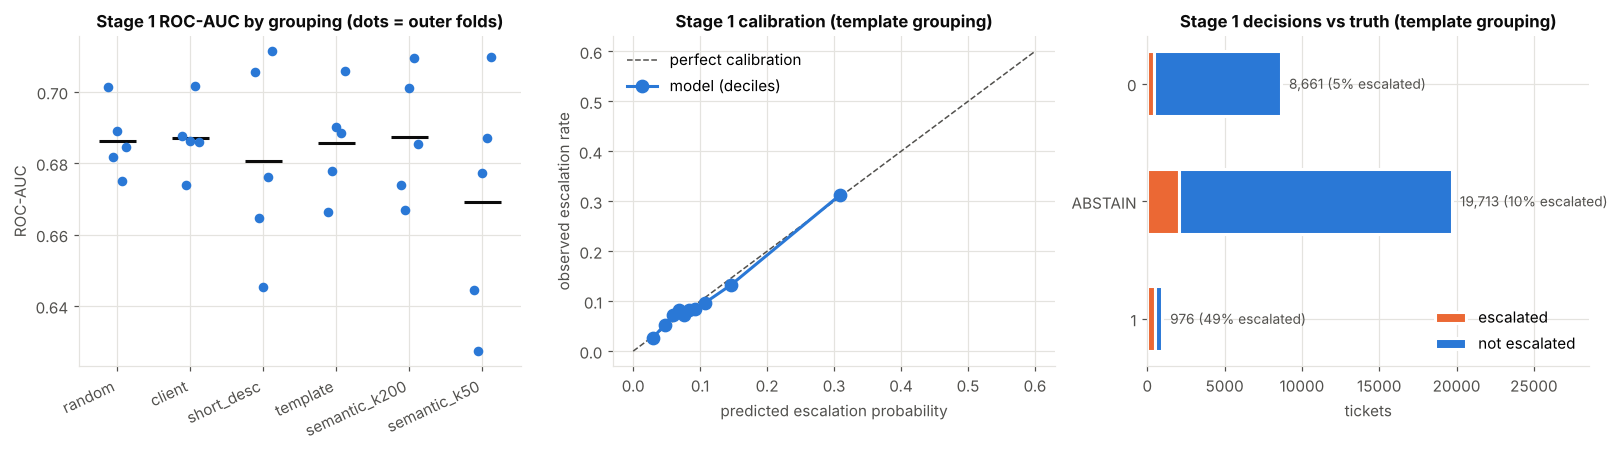

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for i, g in enumerate(GROUPINGS):
    v = s1[s1.grouping == g].AUC
    ax.scatter(np.full(len(v), i) + np.linspace(-.12, .12, len(v)), v, s=28, color=C1, zorder=3)
    ax.hlines(v.mean(), i - .25, i + .25, color=INK, lw=2)
ax.set_xticks(range(len(GROUPINGS))); ax.set_xticklabels(GROUPINGS, rotation=25, ha="right")
ax.set_title("Stage 1 ROC-AUC by grouping (dots = outer folds)"); ax.set_ylabel("ROC-AUC")

# reliability curve, primary grouping
p, _ = s1_oof[PRIMARY_GROUPING]; y = new.y_esc.values
bins = pd.qcut(p, 10, duplicates="drop"); rel = pd.DataFrame({"p": p, "y": y}).groupby(bins).mean()
ax = axes[1]; ax.plot([0, .6], [0, .6], color=INK2, lw=1, ls="--", label="perfect calibration")
ax.plot(rel.p, rel.y, marker="o", ms=8, color=C1, lw=2, label="model (deciles)")
ax.set_xlabel("predicted escalation probability"); ax.set_ylabel("observed escalation rate")
ax.set_title(f"Stage 1 calibration ({PRIMARY_GROUPING} grouping)"); ax.legend(frameon=False)

# where the decisions fall
_, d = s1_oof[PRIMARY_GROUPING]
dec = pd.crosstab(pd.Series(d, name="decision"), pd.Series(np.where(y == 1, "escalated", "not escalated"), name="truth"))
dec = dec.reindex(["1", "ABSTAIN", "0"]).fillna(0)
ax = axes[2]; left = np.zeros(len(dec))
for col, c in [("escalated", C2), ("not escalated", C1)]:
    ax.barh(dec.index, dec[col], left=left, color=c, label=col, height=.55, edgecolor="white", linewidth=2); left += dec[col].values
for i, (n, tot) in enumerate(zip(dec["escalated"], dec.sum(1))):
    ax.text(tot, i, f"  {int(tot):,} ({n / max(tot, 1):.0%} escalated)", va="center", color=INK2, fontsize=9)
ax.set_title(f"Stage 1 decisions vs truth ({PRIMARY_GROUPING} grouping)"); ax.set_xlabel("tickets")
ax.legend(frameon=False, loc="lower right"); ax.set_xlim(0, left.max() * 1.45)
plt.tight_layout()

### Stage 1 alternative output: risk bands

The 0/1/abstain decision answers only about 29% of tickets. A risk band instead gives every in-distribution ticket an answer: the escalation rate actually observed for similar tickets.
* **Band edges** are fixed in advance relative to the ~10% base rate:
  * Low: under 5%
  * Typical: 5–15%
  * Elevated: 15–40%
  * High: 40% or more
* **Rates** below are measured on the **outer test folds** (`template` grouping), so each band label is checked on tickets the model never trained on.
* **Insufficient data:** tickets flagged as out-of-distribution, and any band with fewer than `MIN_SUPPORT` cases, get **INSUFFICIENT DATA** instead of a band.

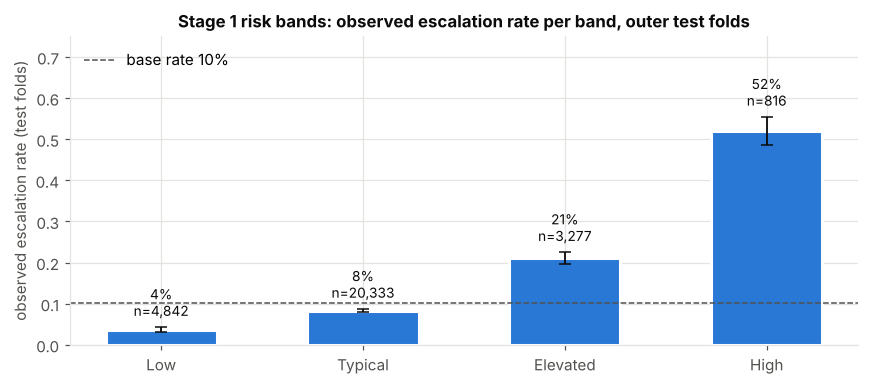

,tickets,share,observed escalation rate,95% CI low,95% CI high,lift vs base
band,,,,,,
Low,4842,0.165,0.037,0.032,0.042,0.362
Typical,20333,0.693,0.083,0.079,0.087,0.815
Elevated,3277,0.112,0.210,0.197,0.225,2.071
High,816,0.028,0.520,0.485,0.554,5.118
INSUFFICIENT DATA,82,0.003,0.085,0.042,0.166,0.841


In [10]:
def to_band(p):
    return np.array(RISK_BAND_NAMES, dtype=object)[np.digitize(p, RISK_BAND_EDGES)]

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; den = 1 + z * z / n; c = (ph + z * z / (2 * n)) / den
    h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return c - h, c + h

p_oof, d_oof = s1_oof[PRIMARY_GROUPING]; y = new.y_esc.values
ood_oof = s1_ood[PRIMARY_GROUPING]          # OOD flags from the same outer test folds
band_oof = np.where(ood_oof, "INSUFFICIENT DATA", to_band(p_oof)).astype(object)

rows = []
for b in RISK_BAND_NAMES + ["INSUFFICIENT DATA"]:
    m = band_oof == b; n = int(m.sum()); k = int(y[m].sum())
    lo, hi = wilson(k, n)
    rows.append({"band": b, "tickets": n, "share": n / len(y), "observed escalation rate": k / n if n else np.nan,
                 "95% CI low": lo, "95% CI high": hi, "lift vs base": (k / n) / y.mean() if n else np.nan})
BAND_TABLE = pd.DataFrame(rows).set_index("band")
for b in RISK_BAND_NAMES:     # a band with too little evidence is not reported as a band
    if BAND_TABLE.loc[b, "tickets"] < MIN_SUPPORT:
        BAND_TABLE.loc[b, "observed escalation rate"] = np.nan

fig, ax = plt.subplots(figsize=(8, 3.6))
bt = BAND_TABLE.loc[RISK_BAND_NAMES]
ax.bar(bt.index, bt["observed escalation rate"], color=C1, width=.55, edgecolor="white", linewidth=2)
ax.errorbar(bt.index, bt["observed escalation rate"],
            yerr=[bt["observed escalation rate"] - bt["95% CI low"], bt["95% CI high"] - bt["observed escalation rate"]],
            fmt="none", ecolor=INK, capsize=4, lw=1.2)
ax.axhline(y.mean(), color=INK2, ls="--", lw=1, label=f"base rate {y.mean():.0%}")
for i, (r, n, hi) in enumerate(zip(bt["observed escalation rate"], bt.tickets, bt["95% CI high"])):
    ax.text(i, hi + .02, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", color=INK, fontsize=9)
ax.legend(frameon=False, loc="upper left")
ax.set_ylim(0, max(.75, bt["95% CI high"].max() + .15)); ax.set_ylabel("observed escalation rate (test folds)")
ax.set_title("Stage 1 risk bands: observed escalation rate per band, outer test folds")
plt.tight_layout()
BAND_TABLE.round(3)

## 6. Stage 2: category / sub-category pair, nested grouped CV across all six groupings

In [11]:
lab = np.where(new.pair.notna())[0]
s2_rows, s2_oof = [], {}
t0 = time.time()
for g in GROUPINGS:
    oof = {"pair": np.empty(len(new), dtype=object), "cat": np.empty(len(new), dtype=object), "mode": np.empty(len(new), dtype=object)}
    for k, (tr, te) in enumerate(split(g, lab, PAIR[lab], N_OUTER)):
        tr, te = lab[tr], lab[te]
        m = fit_stage2(tr, g)
        res, (pair, cat, mode) = eval_stage2(m, te, tr)
        oof["pair"][te], oof["cat"][te], oof["mode"][te] = pair, cat, mode
        s2_rows.append({"grouping": g, "fold": k, **res, "t_pair": m["t_pair"], "t_cat": m["t_cat"], "tau": m["tau"]})
    s2_oof[g] = oof
    print(f"{g:14s} done ({time.time() - t0:.0f}s)")
s2 = pd.DataFrame(s2_rows)
s2.to_csv(ROOT / "artifacts/stage2_fold_results.csv", index=False)
cols2 = ["pair_acc_forced", "cat_acc_forced", "pair_macroF1_forced", "answer_pair", "pair_acc_when_answered",
         "answer_cat_only", "cat_acc_when_cat_only", "abstain", "OOD_abstain", "unseen_label_rows", "unseen_given_pair",
         "unseen_safe", "near_dup_in_train"]
s2_summary = s2.groupby("grouping", sort=False)[cols2].agg(lambda x: f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}")
s2_summary

random         done (235s)
client         done (475s)
short_desc     done (719s)
template       done (1027s)
semantic_k200  done (1305s)
semantic_k50   done (1593s)


,pair_acc_forced,cat_acc_forced,pair_macroF1_forced,answer_pair,pair_acc_when_answered,answer_cat_only,cat_acc_when_cat_only,abstain,OOD_abstain,unseen_label_rows,unseen_given_pair,unseen_safe,near_dup_in_train
grouping,,,,,,,,,,,,,
random,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.992 ± 0.002,1.000 ± 0.000,0.001 ± 0.001,1.000 ± 0.000,0.007 ± 0.001,0.006 ± 0.001,0.000 ± 0.000,nan ± nan,nan ± nan,0.517 ± 0.004
client,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.001,0.993 ± 0.003,1.000 ± 0.000,0.001 ± 0.000,1.000 ± 0.000,0.006 ± 0.002,0.006 ± 0.002,0.000 ± 0.000,nan ± nan,nan ± nan,0.516 ± 0.005
short_desc,0.998 ± 0.001,0.998 ± 0.001,0.998 ± 0.001,0.991 ± 0.002,1.000 ± 0.000,0.002 ± 0.002,0.789 ± 0.246,0.007 ± 0.001,0.005 ± 0.001,0.000 ± 0.000,nan ± nan,nan ± nan,0.309 ± 0.028
template,0.997 ± 0.001,0.998 ± 0.001,0.991 ± 0.004,0.990 ± 0.004,1.000 ± 0.000,0.003 ± 0.001,0.951 ± 0.061,0.007 ± 0.004,0.005 ± 0.003,0.000 ± 0.000,nan ± nan,nan ± nan,0.198 ± 0.018
semantic_k200,0.975 ± 0.046,0.990 ± 0.017,0.935 ± 0.073,0.943 ± 0.058,1.000 ± 0.000,0.030 ± 0.024,0.990 ± 0.018,0.027 ± 0.041,0.002 ± 0.003,0.000 ± 0.000,nan ± nan,nan ± nan,0.004 ± 0.002
semantic_k50,0.704 ± 0.269,0.824 ± 0.194,0.486 ± 0.103,0.480 ± 0.249,0.952 ± 0.062,0.264 ± 0.179,0.945 ± 0.058,0.256 ± 0.256,0.002 ± 0.002,0.145 ± 0.289,0.003 ± 0.000,0.997 ± 0.000,0.000 ± 0.001


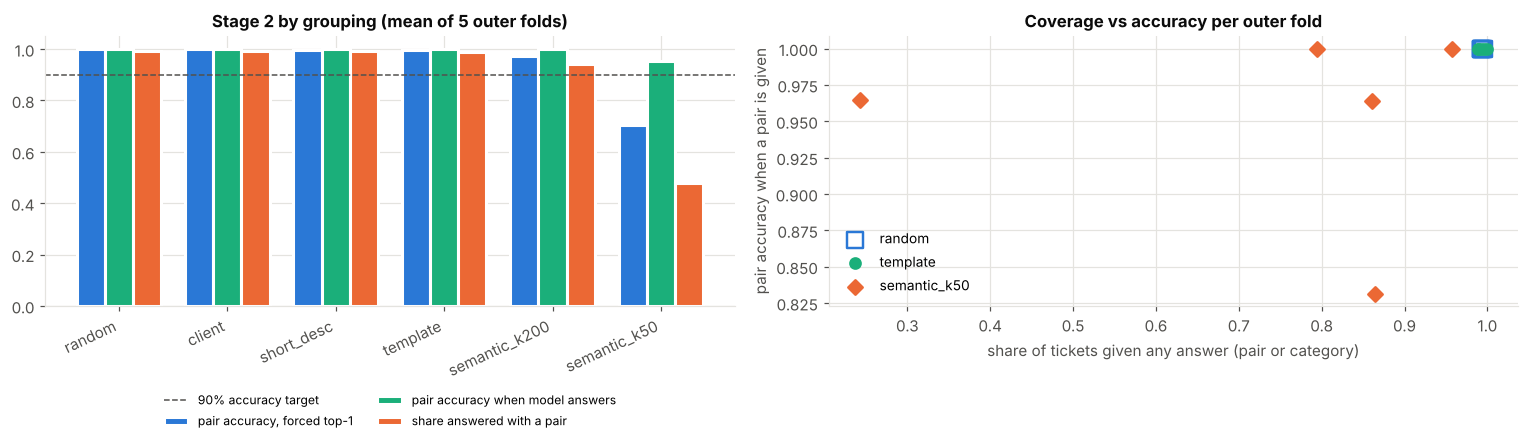

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]; w = .26; xs = np.arange(len(GROUPINGS))
agg = s2.groupby("grouping", sort=False).agg(f=("pair_acc_forced", "mean"), a=("pair_acc_when_answered", "mean"),
                                             cov=("answer_pair", "mean"), co=("answer_cat_only", "mean"))
agg = agg.reindex(GROUPINGS)
ax.bar(xs - w, agg.f, w, color=C1, label="pair accuracy, forced top-1", edgecolor="white", linewidth=2)
ax.bar(xs, agg.a, w, color=C3, label="pair accuracy when model answers", edgecolor="white", linewidth=2)
ax.bar(xs + w, agg["cov"], w, color=C2, label="share answered with a pair", edgecolor="white", linewidth=2)
ax.set_xticks(xs); ax.set_xticklabels(GROUPINGS, rotation=25, ha="right"); ax.set_ylim(0, 1.05)
ax.axhline(STAGE2_ACC_TARGET, color=INK2, ls="--", lw=1, label=f"{STAGE2_ACC_TARGET:.0%} accuracy target")
ax.set_title("Stage 2 by grouping (mean of 5 outer folds)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)

# coverage-accuracy trade-off, primary grouping, from out-of-fold forced predictions + confidences
ax = axes[1]
for g, c, mk, sz in [("random", C1, "s", 110), (PRIMARY_GROUPING, C3, "o", 45), ("semantic_k50", C2, "D", 45)]:
    r = s2[s2.grouping == g]
    ax.scatter(r.answer_pair + r.answer_cat_only, r.pair_acc_when_answered, s=sz, marker=mk, label=g,
               facecolors="none" if g == "random" else c, edgecolors=c, linewidths=1.6, zorder=3)
ax.set_xlabel("share of tickets given any answer (pair or category)"); ax.set_ylabel("pair accuracy when a pair is given")
ax.set_title("Coverage vs accuracy per outer fold"); ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

In [13]:
# where does stage 2 go wrong? top confusions under the primary grouping (forced top-1)
o = s2_oof[PRIMARY_GROUPING]; m_ = new.pair.notna().values
conf = pd.DataFrame({"truth": PAIR[m_], "pred": o["pair"][m_], "mode": o["mode"][m_]})
wrong = conf[conf.truth != conf.pred]
print(f"forced-top-1 errors: {len(wrong):,} of {len(conf):,}; of those, model abstained or gave category-only on "
      f"{(wrong['mode'] != 'pair').mean():.0%}")
crossed = (wrong.truth.str.split(" || ", regex=False).str[0] != wrong.pred.str.split(" || ", regex=False).str[0]).mean()
print(f"errors that crossed a category boundary: {crossed:.0%}")
wrong.groupby(["truth", "pred"]).size().sort_values(ascending=False).head(10).rename("count").to_frame()

forced-top-1 errors: 81 of 28,750; of those, model abstained or gave category-only on 100%
errors that crossed a category boundary: 86%


,,count
truth,pred,
Portfolio Tools || Cash balance query,Reconciliation || Cash break,10
Portfolio Tools || Model portfolio question,Wealth || Model assignment,7
Reference Data || Instrument attribute correction,Reporting || Report totals incorrect,7
Investor Services || Document not visible,Analytics || Performance figure question,5
Pre-Trade Rules || Rule exception review,Pre-Trade Rules || Rule result query,4
Portfolio Tools || Model portfolio question,Analytics || Recalculation request,4
Private Markets Data || Valuation correction,Reporting || Report totals incorrect,3
Investor Services || Document not visible,Accounting || Cash flow missing,3
Analytics || Risk figure question,Reporting || New report request,2


## 7. Temporal hold-out: train Jan–Apr, test May–Jun

This mirrors how the model would actually be used, scoring tickets that arrive after the training period. Tuning happens inside the training months only, using `template`-grouped inner folds.

In [14]:
tr_t = np.where(new.CREATED < "2024-05-01")[0]; te_t = np.where(new.CREATED >= "2024-05-01")[0]
m1 = fit_stage1(tr_t, PRIMARY_GROUPING, "both"); r1, _, _ = eval_stage1(m1, te_t, tr_t)
tr2, te2 = np.intersect1d(tr_t, lab), np.intersect1d(te_t, lab)
m2 = fit_stage2(tr2, PRIMARY_GROUPING); r2, _ = eval_stage2(m2, te2, tr2)
# share of May–Jun templates never seen in Jan–Apr
unseen_tmpl = (~new.g_template.iloc[te_t].isin(set(new.g_template.iloc[tr_t]))).mean()
print(f"train {len(tr_t):,} | test {len(te_t):,} | test templates unseen in training: {unseen_tmpl:.1%}")
pd.DataFrame({"stage 1 (escalation)": pd.Series(r1), "stage 2 (pair)": pd.Series(r2)}).round(3).fillna("")

train 19,405 | test 9,945 | test templates unseen in training: 7.4%


,stage 1 (escalation),stage 2 (pair)
AUC,0.681,
Brier,0.086,
C,0.003,0.1
NPV_0,0.948,
OOD_abstain,0.0,0.001
PR_AUC,0.26,
abstain,,0.002
answer_cat_only,,0.006
answer_pair,,0.992
base_rate,0.103,


## 8. Final model: fit on the whole new set, then run the old-set refusal test

`C`, the refusal thresholds and the OOD cut-off come from inner cross-validation over all the new data. The final model uses **one shared similarity cut-off** for both stages, so the two stages always agree on whether a ticket is out of distribution. The old set is then scored with **no retraining or tuning**.

**How to read the old-set stage-2 result.**
* The two taxonomies were generated separately.
* Many old labels are the same request under a different name. For example, old *Manager report chase* corresponds to new *Fund report chase*.
* Without an agreed mapping between the two schemes, a mismatched label can't automatically be called a hallucination.

So every old-set answer is put in one of these buckets:

| Bucket | Meaning |
|---|---|
| exact | same category and sub-category |
| same sub-category name | the sub-category text matches; only the category name differs |
| different label, needs mapping review | the model answered with a label from the new scheme. A person needs to decide whether it is equivalent |
| abstained | no answer given |

The "different label" mappings are listed for review. They are not counted as correct.

In [15]:
final1 = fit_stage1(idx_all, PRIMARY_GROUPING, "both")
final2 = fit_stage2(lab, PRIMARY_GROUPING)
TAU = final2["tau"]; final1["tau"] = TAU          # one shared out-of-distribution cut-off for both stages
for name, m in [("stage 1", final1), ("stage 2", final2)]:
    print(name, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items() if k not in ("model", "last_ood")})
joblib.dump({"stage1": {k: v for k, v in final1.items() if k != "last_ood"}, "stage2": final2, "tau": TAU,
             "struct_levels": STRUCT_LEVELS, "train_embeddings": E_new, "band_table": BAND_TABLE,
             "config": dict(STAGE1_PREC_TARGET=STAGE1_PREC_TARGET, STAGE1_NPV_TARGET=STAGE1_NPV_TARGET,
                            STAGE2_ACC_TARGET=STAGE2_ACC_TARGET, MIN_SUPPORT=MIN_SUPPORT, OOD_PERCENTILE=OOD_PERCENTILE,
                            RISK_BAND_EDGES=RISK_BAND_EDGES, RISK_BAND_NAMES=RISK_BAND_NAMES)},
            ROOT / "artifacts/final_model.joblib")
print("saved artifacts/final_model.joblib")

stage 1 {'C': 0.003, 't_lo': 0.0608, 't_hi': 0.3081, 'tau': 0.776, 'feat': 'both'}
stage 2 {'C': 0.1, 't_pair': 0.7593, 't_cat': 0.5731, 'tau': 0.776}
saved artifacts/final_model.joblib


In [16]:
X_struct_old, _ = onehot(old, STRUCT_COLS, STRUCT_LEVELS)        # unseen levels -> all-zero one-hot
unseen_struct = ~np.isin(old.CLIENT_SUPPORT.astype(str), STRUCT_LEVELS["CLIENT_SUPPORT"]) | \
                ~np.isin(old.PRIORITY.astype(str), STRUCT_LEVELS["PRIORITY"])
sim_old = max_sim(E_old, E_new)
ood_old = sim_old < TAU
p_old = final1["model"].predict_proba(np.hstack([E_old, X_struct_old]))[:, 1]
d_old = stage1_decide(p_old, final1["t_lo"], final1["t_hi"], ood_old | unseen_struct)
band_old = np.where(ood_old | unseen_struct, "INSUFFICIENT DATA", to_band(p_old)).astype(object)
y_old = old.y_esc.values

print(f"Out-of-distribution share: new-set validation ≈ {OOD_PERCENTILE / 100:.0%} by construction | old set {ood_old.mean():.1%}")
print(f"Median similarity to nearest new-set description: old {np.median(sim_old):.3f}")
print(f"\nStage 1 on old set: true escalation rate {y_old.mean():.1%}, mean predicted probability {p_old.mean():.1%}")
print(f"  ROC-AUC on old (does the ranking transfer?): {roc_auc_score(y_old, p_old):.3f}")
display(pd.crosstab(pd.Series(d_old, name="0/1 decision"), pd.Series(np.where(y_old == 1, "escalated", "not escalated"), name="truth"), margins=True))
cmp = pd.DataFrame({"old tickets": pd.Series(band_old).value_counts(),
                    "old observed rate": pd.Series(y_old).groupby(band_old).mean(),
                    "rate this band promised (new test folds)": BAND_TABLE["observed escalation rate"]}).reindex(RISK_BAND_NAMES + ["INSUFFICIENT DATA"])
display(cmp.round(3))
print("Reading: the ranking partly transfers (higher bands still escalate more), but every band's rate is far above what "
      "it promised. A base-rate shift like this cannot be seen from one ticket. It needs population-level monitoring: "
      "compare each band's promised rate with the rate actually observed each week, and retrain when they diverge.")

Out-of-distribution share: new-set validation ≈ 1% by construction | old set 56.4%
Median similarity to nearest new-set description: old 0.745

Stage 1 on old set: true escalation rate 85.0%, mean predicted probability 8.1%
  ROC-AUC on old (does the ranking transfer?): 0.745
Reading: the ranking partly transfers (higher bands still escalate more), but every band's rate is far above what it promised. A base-rate shift like this cannot be seen from one ticket. It needs population-level monitoring: compare each band's promised rate with the rate actually observed each week, and retrain when they diverge.


truth,escalated,not escalated,All
0/1 decision,,,
0,262,54,316
1,11,0,11
ABSTAIN,1967,342,2309
All,2240,396,2636


,old tickets,old observed rate,rate this band promised (new test folds)
Low,192,0.781,0.037
Typical,797,0.941,0.083
Elevated,150,0.993,0.210
High,9,1.000,0.520
INSUFFICIENT DATA,1488,0.794,0.085


In [17]:
P_old = final2["model"].predict_proba(E_old); classes = final2["model"].classes_
pair_o, cat_o, mode_o = stage2_decide(P_old, classes, final2["t_pair"], final2["t_cat"], ood_old)
labelled = old.pair.notna().to_numpy()
old_pair = old.pair.to_numpy(dtype=object); ycat = old.CATEGORY.to_numpy(dtype=object)
ysub = old["Sub Category"].to_numpy(dtype=object)
known_cats = {c.split(" || ")[0] for c in classes}
case = np.where(np.isin(old_pair, classes), "A: pair in new label set",
        np.where(pd.Series(ycat).isin(known_cats), "B: category in new set, pair not", "C: category not in new set"))

def outcome(i):
    m = mode_o[i]
    if m == "ABSTAIN": return "abstained"
    if m == "pair":
        if pair_o[i] == old_pair[i]: return "exact"
        if pair_o[i].split(" || ")[1] == ysub[i]: return "same sub-category name"
        return "different label, needs mapping review"
    if cat_o[i] == ycat[i]: return "exact (category only)"
    return "different label, needs mapping review"

out = pd.DataFrame({"case": case, "outcome": [outcome(i) for i in range(len(old))],
                    "true": old_pair, "answer": np.where(mode_o == "pair", pair_o, np.where(mode_o == "category", cat_o + " || (category only)", "ABSTAIN"))})[labelled]
print(f"Old tickets scored: {len(out):,} (excluded {(~labelled).sum()} with no category label)")
display(pd.crosstab(out.case, out.outcome, margins=True))
print(f"\nabstained {(out.outcome == 'abstained').mean():.1%} | exact {out.outcome.str.startswith('exact').mean():.1%} | "
      f"same sub-category name {(out.outcome == 'same sub-category name').mean():.1%} | "
      f"needs mapping review {(out.outcome.str.startswith('different')).mean():.1%}")
print("\nLabel mappings the model proposed for old tickets (for human review, not counted as correct):")
out[out.outcome.str.startswith("different")].groupby(["true", "answer"]).size().sort_values(ascending=False).head(12).rename("tickets").to_frame()

Old tickets scored: 2,626 (excluded 10 with no category label)

abstained 56.7% | exact 9.4% | same sub-category name 21.5% | needs mapping review 12.4%

Label mappings the model proposed for old tickets (for human review, not counted as correct):


outcome,abstained,"different label, needs mapping review",exact,same sub-category name,All
case,,,,,
A: pair in new label set,53,0,247,0,300
"B: category in new set, pair not",191,121,0,48,360
C: category not in new set,1244,205,0,517,1966
All,1488,326,247,565,2626


,,tickets
true,answer,
Data Coverage || Manager report chase,Private Markets Data || Fund report chase,60
Workflow & Setup || Approval workflow change,Configuration || Workflow change,59
Workflow & Setup || Add field value,Configuration || Field value addition,48
Reporting || Export to spreadsheet,Reporting || Export columns missing,44
Investor Documents || Quarterly statement,Investor Services || Statement query,35
Analytics || Instrument data question,Reference Data || Instrument attribute correction,34
Wealth || Model assignment question,Wealth || Model assignment,30
Analytics || Instrument data question,Reference Data || New instrument request,13
Investor Portal || Navigation question,Investor Services || Document not visible,1


## 9. Scoring a new ticket

`score_ticket()` is the function a downstream system would call. It returns the 0/1/abstain decision **and** the risk band, plus the reason for every refusal. The examples include an off-topic request to show the model refusing.

In [18]:
def score_ticket(short_description, description, priority="3 - Moderate", client_support="Standard"):
    text = clean_text(short_description, description)
    e = embedder.encode([text])
    xs, _ = onehot(pd.DataFrame({"PRIORITY": [priority], "CLIENT_SUPPORT": [client_support]}), STRUCT_COLS, STRUCT_LEVELS)
    sim = float(max_sim(e, E_new)[0]); ood = sim < TAU
    unseen = priority not in STRUCT_LEVELS["PRIORITY"] or client_support not in STRUCT_LEVELS["CLIENT_SUPPORT"]
    p = float(final1["model"].predict_proba(np.hstack([e, xs]))[0, 1])
    d1 = stage1_decide(np.array([p]), final1["t_lo"], final1["t_hi"], np.array([ood or unseen]))[0]
    band = "INSUFFICIENT DATA" if (ood or unseen) else to_band(np.array([p]))[0]
    band_rate = BAND_TABLE.loc[band, "observed escalation rate"] if band in RISK_BAND_NAMES else np.nan
    P = final2["model"].predict_proba(e)
    pair, cat, mode = stage2_decide(P, final2["model"].classes_, final2["t_pair"], final2["t_cat"], np.array([ood]))
    Pc, _ = cat_probs(P, final2["model"].classes_)
    reasons = []
    if ood: reasons.append(f"description unlike training data (similarity {sim:.2f} < {TAU:.2f})")
    if unseen: reasons.append("priority / support tier not seen in training")
    if d1 == "ABSTAIN" and not (ood or unseen):
        reasons.append(f"escalation p={p:.2f} between validated thresholds [{final1['t_lo']:.2f}, {final1['t_hi']:.2f})")
    if mode[0] == "category": reasons.append("sub-category confidence below validated threshold; category only")
    if mode[0] == "ABSTAIN" and not ood: reasons.append("category confidence below validated threshold")
    return {"escalation (0/1)": d1, "risk band": band,
            "similar tickets escalated": "-" if np.isnan(band_rate) else f"{band_rate:.0%} (n={int(BAND_TABLE.loc[band, 'tickets']):,})",
            "p_escalation": round(p, 3),
            "category": cat[0] if mode[0] in ("pair", "category") else "INSUFFICIENT DATA",
            "sub_category": pair[0].split(" || ")[1] if mode[0] == "pair" else "INSUFFICIENT DATA",
            "pair_conf": round(float(P.max()), 3), "category_conf": round(float(Pc.max()), 3),
            "nearest_similarity": round(sim, 3), "reasons": "; ".join(reasons) or "-"}

examples = [
    ("NAV difference", "The March 2024 NAV for Fund FD-210 differs from the administrator by USD 2.1m. Please investigate urgently.", "1 - Critical", "Premium East"),
    ("Remove user", "Please remove access for a colleague who has left the firm.", "4 - Low", "Standard"),
    ("Statement query", "The commitment on the Q1 2024 statement for Fund FD-77 looks wrong.", "2 - High", "Dedicated Team A"),
    ("Office party", "Can you recommend a good venue for our team's year-end dinner?", "3 - Moderate", "Standard"),
]
pd.DataFrame([score_ticket(*ex) for ex in examples], index=[e[0] for e in examples])

,escalation (0/1),risk band,similar tickets escalated,p_escalation,category,sub_category,pair_conf,category_conf,nearest_similarity,reasons
NAV difference,1,High,52% (n=816),0.576,Accounting,NAV difference,1.000,1.000,0.952,-
Remove user,0,Low,"4% (n=4,842)",0.009,User Setup,Remove user,0.954,0.998,0.796,-
Statement query,ABSTAIN,Elevated,"21% (n=3,277)",0.186,Investor Services,Statement query,0.994,0.996,0.910,escalation p=0.19 between validated thresholds...
Office party,ABSTAIN,INSUFFICIENT DATA,-,0.144,INSUFFICIENT DATA,INSUFFICIENT DATA,0.105,0.175,0.201,description unlike training data (similarity 0...


## 10. Summary

In [19]:
def ms(df, g, c): v = df[df.grouping == g][c]; return f"{np.nanmean(v):.3f} ± {np.nanstd(v):.3f}"
summary = pd.DataFrame({g: {
    "S1 ROC-AUC": ms(s1, g, "AUC"), "S1 PR-AUC": ms(s1, g, "PR_AUC"),
    "S1 coverage (answers 0/1)": ms(s1, g, "coverage"), "S1 precision of '1'": ms(s1, g, "precision_1"),
    "S1 NPV of '0'": ms(s1, g, "NPV_0"),
    "S2 pair acc (forced)": ms(s2, g, "pair_acc_forced"), "S2 category acc (forced)": ms(s2, g, "cat_acc_forced"),
    "S2 share answered with pair": ms(s2, g, "answer_pair"), "S2 pair acc when answered": ms(s2, g, "pair_acc_when_answered"),
    "S2 share category-only": ms(s2, g, "answer_cat_only"), "S2 abstain": ms(s2, g, "abstain"),
    "S2 unseen-pair tickets given a pair (wrong)": ms(s2, g, "unseen_given_pair"),
    "S2 unseen-pair tickets handled safely": ms(s2, g, "unseen_safe"),
    "near-duplicate of test in train": ms(s2, g, "near_dup_in_train")} for g in GROUPINGS}).T
summary.to_csv(ROOT / "artifacts/summary_by_grouping.csv")
summary

,S1 ROC-AUC,S1 PR-AUC,S1 coverage (answers 0/1),S1 precision of '1',S1 NPV of '0',S2 pair acc (forced),S2 category acc (forced),S2 share answered with pair,S2 pair acc when answered,S2 share category-only,S2 abstain,S2 unseen-pair tickets given a pair (wrong),S2 unseen-pair tickets handled safely,near-duplicate of test in train
random,0.686 ± 0.009,0.265 ± 0.020,0.312 ± 0.027,0.493 ± 0.043,0.952 ± 0.005,1.000 ± 0.000,1.000 ± 0.000,0.992 ± 0.002,1.000 ± 0.000,0.001 ± 0.001,0.007 ± 0.001,nan ± nan,nan ± nan,0.517 ± 0.004
client,0.687 ± 0.009,0.264 ± 0.008,0.327 ± 0.011,0.506 ± 0.011,0.952 ± 0.005,1.000 ± 0.000,1.000 ± 0.000,0.993 ± 0.003,1.000 ± 0.000,0.001 ± 0.000,0.006 ± 0.002,nan ± nan,nan ± nan,0.516 ± 0.005
short_desc,0.681 ± 0.025,0.263 ± 0.026,0.295 ± 0.028,0.508 ± 0.034,0.952 ± 0.007,0.998 ± 0.001,0.998 ± 0.001,0.991 ± 0.002,1.000 ± 0.000,0.002 ± 0.002,0.007 ± 0.001,nan ± nan,nan ± nan,0.309 ± 0.028
template,0.686 ± 0.013,0.269 ± 0.016,0.328 ± 0.042,0.500 ± 0.050,0.951 ± 0.006,0.997 ± 0.001,0.998 ± 0.001,0.990 ± 0.004,1.000 ± 0.000,0.003 ± 0.001,0.007 ± 0.004,nan ± nan,nan ± nan,0.198 ± 0.018
semantic_k200,0.687 ± 0.016,0.269 ± 0.013,0.285 ± 0.062,0.528 ± 0.036,0.954 ± 0.008,0.975 ± 0.046,0.990 ± 0.017,0.943 ± 0.058,1.000 ± 0.000,0.030 ± 0.024,0.027 ± 0.041,nan ± nan,nan ± nan,0.004 ± 0.002
semantic_k50,0.669 ± 0.030,0.252 ± 0.032,0.202 ± 0.062,0.532 ± 0.084,0.951 ± 0.013,0.704 ± 0.269,0.824 ± 0.194,0.480 ± 0.249,0.952 ± 0.062,0.264 ± 0.179,0.256 ± 0.256,0.003 ± 0.000,0.997 ± 0.000,0.000 ± 0.001


## 11. Export all test results

Every result table above is written to `artifacts/results/` as CSV. `src/build_results_workbook.py` turns them into `artifacts/test_results.xlsx`.

In [20]:
RES = ROOT / "artifacts/results"; RES.mkdir(exist_ok=True)
tables = {
    "grouping_systems": grouping_summary.reset_index(),
    "stage1_folds": s1,
    "stage1_ablation_folds": abl,
    "stage1_decisions_vs_truth": dec.reset_index(),
    "stage1_risk_bands": BAND_TABLE.reset_index(),
    "stage2_folds": s2,
    "stage2_top_confusions": wrong.groupby(["truth", "pred"]).size().sort_values(ascending=False).head(25).rename("count").reset_index(),
    "temporal_holdout": pd.DataFrame({"metric": list(r1) + list(r2),
                                      "stage": ["stage 1 (escalation)"] * len(r1) + ["stage 2 (pair)"] * len(r2),
                                      "value": list(r1.values()) + list(r2.values())}),
    "old_stage1_decisions": pd.crosstab(pd.Series(d_old, name="decision"),
                                        pd.Series(np.where(y_old == 1, "escalated", "not escalated"), name="truth")).reset_index(),
    "old_stage1_bands": cmp.reset_index().rename(columns={"index": "band"}),
    "old_stage2_outcomes": pd.crosstab(out.case, out.outcome).reset_index(),
    "old_stage2_mappings_for_review": out[out.outcome.str.startswith("different")].groupby(["true", "answer"]).size()
                                         .sort_values(ascending=False).rename("tickets").reset_index(),
    "example_tickets": pd.DataFrame([score_ticket(*ex) for ex in examples], index=[e[0] for e in examples]).reset_index()
                         .rename(columns={"index": "example"}),
    "final_model_settings": pd.DataFrame([
        {"stage": "stage 1", "C": final1["C"], "t_lo (say 0 below)": final1["t_lo"], "t_hi (say 1 at/above)": final1["t_hi"], "shared OOD similarity cut-off": TAU},
        {"stage": "stage 2", "C": final2["C"], "t_pair": final2["t_pair"], "t_cat": final2["t_cat"], "shared OOD similarity cut-off": TAU}]),
    "run_info": pd.DataFrame({"item": ["new cases", "labelled pairs", "old cases", "outer folds", "inner folds", "C grid",
                                       "stage 1 precision target", "stage 1 NPV target", "stage 2 accuracy target", "min support",
                                       "OOD percentile", "primary grouping", "novelty grouping", "risk band edges"],
                              "value": [len(new), int(new.pair.notna().sum()), len(old), N_OUTER, N_INNER, str(C_GRID),
                                        STAGE1_PREC_TARGET, STAGE1_NPV_TARGET, STAGE2_ACC_TARGET, MIN_SUPPORT, OOD_PERCENTILE,
                                        PRIMARY_GROUPING, NOVELTY_GROUPING, str(RISK_BAND_EDGES)]}),
}
for name, df in tables.items():
    df.to_csv(RES / f"{name}.csv", index=False)
print(f"wrote {len(tables)} tables to {RES}")

wrote 15 tables to /home/claude/project/artifacts/results
